In [87]:
%matplotlib widget
import geopandas as gpd
import pandas as pd
from matplotlib import pyplot as plt
from pyproj import CRS
from os import getcwd
from pathlib import Path
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import usaddress
getcwd()
data_path = Path('Data')/ 'ward_boundaries.geojson'

In [88]:
ward_data = gpd.read_file(data_path)
ward_data = ward_data.dropna() # investigation showed the NaN row was some islands in Lacamas lake lol
crs_camas = ward_data.crs
ward_data

,OBJECTID,Ward,PublishDt,geometry
0,1,2.0,1793389813000,"MULTIPOLYGON (((-122.46384 45.65643, -122.4689..."
1,2,3.0,1793389813000,"POLYGON ((-122.45519 45.57977, -122.45519 45.5..."
3,4,1.0,1793389813000,"MULTIPOLYGON (((-122.40617 45.60458, -122.4066..."


In [89]:
# Make Ward data categorical so it's not read as continuous
# 1. Convert Ward to string or categorical so GeoPandas treats them as discrete bins
ward_data['Ward_Cat'] = ward_data['Ward'].astype(int).astype(str)
ward_data['Ward_Cat'] = 'Ward ' + ward_data['Ward_Cat']  # Optional: Label them nicely ("Ward 1", etc.)
ward_data

,OBJECTID,Ward,PublishDt,geometry,Ward_Cat
0,1,2.0,1793389813000,"MULTIPOLYGON (((-122.46384 45.65643, -122.4689...",Ward 2
1,2,3.0,1793389813000,"POLYGON ((-122.45519 45.57977, -122.45519 45.5...",Ward 3
3,4,1.0,1793389813000,"MULTIPOLYGON (((-122.40617 45.60458, -122.4066...",Ward 1


In [90]:
# Make councilors dictionary
ward_councilors = {
    1: ["Marilyn Boerke", "John Nohr"],
    2: ["Martin Elzingre", "Tim Hein"],
    3: ["Jennifer Senescu", "Mahsa Eshghi"],
}

# Add councilors 
ward_data['Councilors'] = ward_data['Ward'].map(ward_councilors).apply(
    lambda names: " & ".join(names) if isinstance(names, list) else names
)

# Optional: Add the At-Large representative as a note or column
at_large_member = "John Svilarich"
ward_data['At_Large'] = at_large_member
ward_data

,OBJECTID,Ward,PublishDt,geometry,Ward_Cat,Councilors,At_Large
0,1,2.0,1793389813000,"MULTIPOLYGON (((-122.46384 45.65643, -122.4689...",Ward 2,Martin Elzingre & Tim Hein,John Svilarich
1,2,3.0,1793389813000,"POLYGON ((-122.45519 45.57977, -122.45519 45.5...",Ward 3,Jennifer Senescu & Mahsa Eshghi,John Svilarich
3,4,1.0,1793389813000,"MULTIPOLYGON (((-122.40617 45.60458, -122.4066...",Ward 1,Marilyn Boerke & John Nohr,John Svilarich


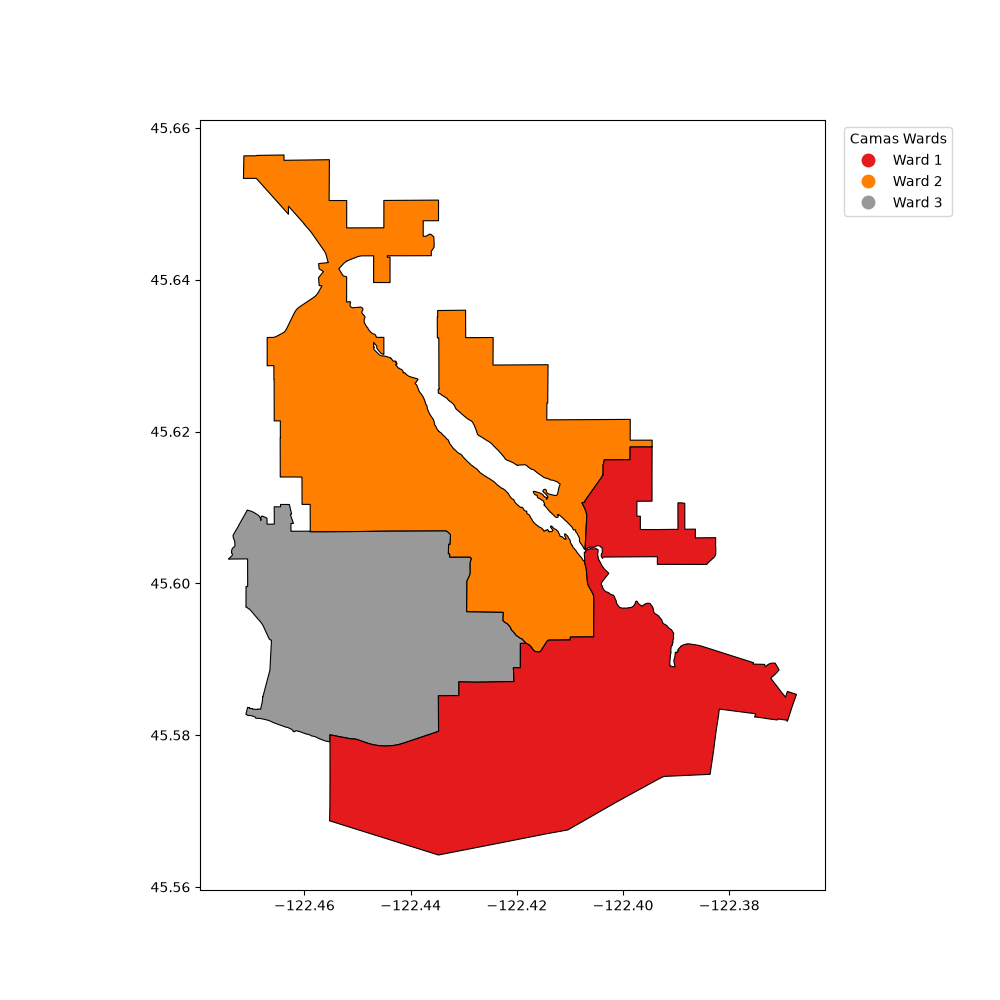

In [91]:
fig,ax = plt.subplots(figsize = (10,10))
ward_data.plot(
    column='Ward_Cat',
    ax=ax,
    legend=True,
    cmap='Set1',          # Qualitative colormap for discrete classes
    categorical=True,     # Forces categorical classification instead of continuous
    edgecolor='black',    # Outlines polygons for better separation
    linewidth=0.8,
    legend_kwds={
        'title': 'Camas Wards',
        'loc': 'upper left',
        'bbox_to_anchor': (1.02, 1)  # Moves the legend outside to the right
    }
)
plt.show()

In [92]:
# Address cleaning
def clean_us_address(raw_address):
    """
    Parses messy US addresses, strips unit/apartment numbers (which throw off geocoders),
    and reconstructs a standardized string: 'Street Number Street Name, City, State Zip'
    """
    if not isinstance(raw_address, str) or not raw_address.strip():
        return None
    
    try:
        # Tag the components using Conditional Random Fields
        tagged_dict, address_type = usaddress.tag(raw_address)
    except usaddress.RepeatedLabelError:
        # Fallback if the address contains repeating ambiguous words
        return raw_address.strip()
    
    # Extract key parts safely
    num = tagged_dict.get('AddressNumber', '')
    predir = tagged_dict.get('StreetNamePreDirectional', '')
    street = tagged_dict.get('StreetName', '')
    postdir = tagged_dict.get('StreetNamePostDirectional', '')
    st_type = tagged_dict.get('StreetNamePostType', '')
    city = tagged_dict.get('PlaceName', '')
    state = tagged_dict.get('StateName', '')
    zip_code = tagged_dict.get('ZipCode', '')
    
    # Assemble street line (skipping Apt/Suite numbers as geocoders match better at street level)
    street_parts = [num, predir, street, st_type, postdir]
    street_line = " ".join([p for p in street_parts if p]).strip()
    
    # Assemble standard format
    city_state_zip = f"{city}, {state} {zip_code}".strip(", ")
    
    if street_line and city_state_zip:
        return f"{street_line}, {city_state_zip}"
    elif street_line:
        return street_line
    return raw_address.strip()


addresses = [
    '863 NW Ivy Street, Camas',
    '1900 NW 23rd Circle Camas, Washington 98607'
    ]
addresses = [clean_us_address(address) for address in addresses]

df = pd.DataFrame({"raw_input": addresses})
df["clean_address"] = df["raw_input"].apply(clean_us_address)
df

,raw_input,clean_address
0,"863 NW Ivy Street, Camas","863 NW Ivy Street, Camas"
1,"1900 NW 23rd Circle, Camas, Washington 98607","1900 NW 23rd Circle, Camas, Washington 98607"


In [93]:
# Geolocating
# Initialize free OpenStreetMap Nominatim geocoder
# Note: Always pass a unique `user_agent` string per Nominatim usage guidelines
geolocator = Nominatim(user_agent="my_us_address_cleaner_app")

# Wrap with RateLimiter to adhere to Nominatim's 1-request-per-second rule
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1.0)

# Perform geocoding
df["location"] = df["clean_address"].apply(geocode)

# Extract coordinates and full returned address
df["latitude"] = df["location"].apply(lambda loc: loc.latitude if loc else None)
df["longitude"] = df["location"].apply(lambda loc: loc.longitude if loc else None)

# -------------------------------------------------------------
# 4. Convert to GeoPandas DataFrame
# -------------------------------------------------------------
gdf_addresses = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df.longitude, df.latitude), 
    crs="EPSG:4326"
)
gdf_addresses = gdf_addresses.to_crs(crs=crs_camas)
gdf_addresses

,raw_input,clean_address,location,latitude,longitude,geometry
0,"863 NW Ivy Street, Camas","863 NW Ivy Street, Camas","(863, Northwest Ivy Street, Camas, Clark Count...",45.586241,-122.420243,POINT (-122.42024 45.58624)
1,"1900 NW 23rd Circle, Camas, Washington 98607","1900 NW 23rd Circle, Camas, Washington 98607","(1900, Northwest 23rd Circle, Camas, Clark Cou...",45.596576,-122.428269,POINT (-122.42827 45.59658)


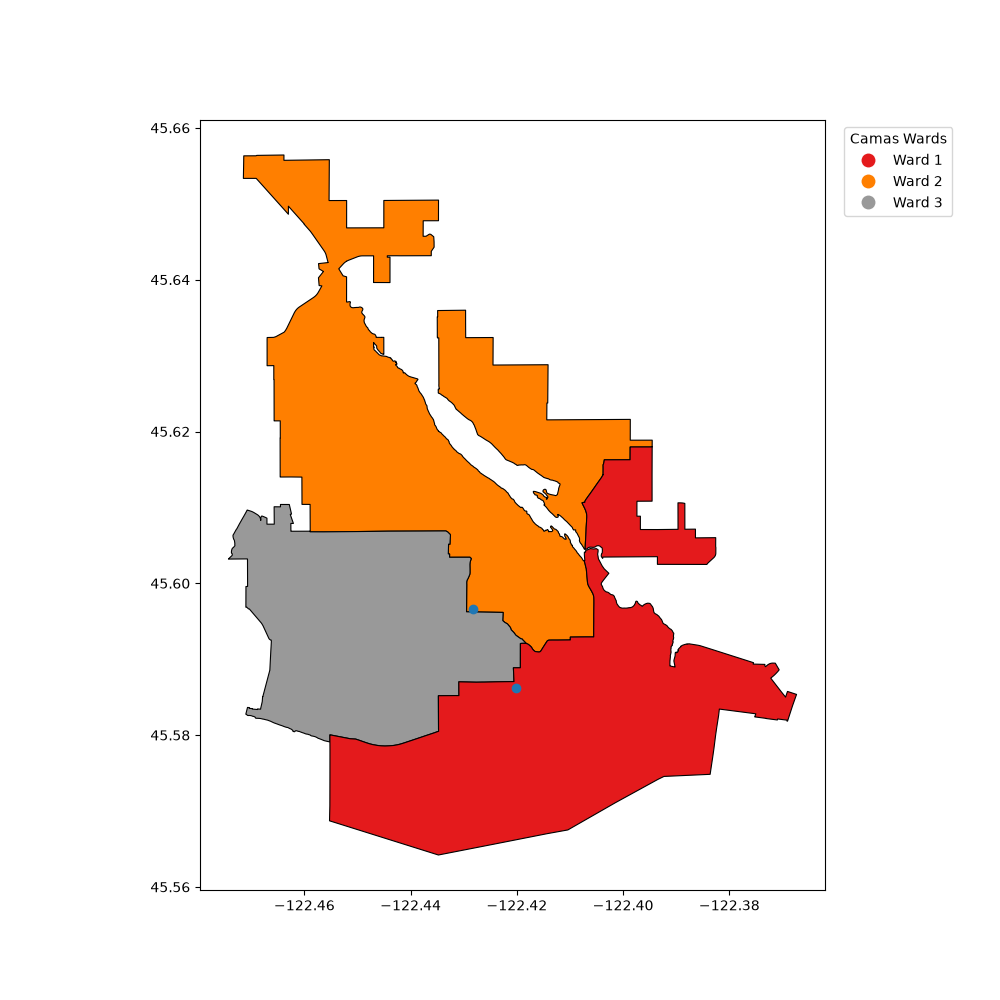

In [94]:
fig,ax = plt.subplots(figsize = (10,10))
ward_data.plot(
    column='Ward_Cat',
    ax=ax,
    legend=True,
    cmap='Set1',          # Qualitative colormap for discrete classes
    categorical=True,     # Forces categorical classification instead of continuous
    edgecolor='black',    # Outlines polygons for better separation
    linewidth=0.8,
    legend_kwds={
        'title': 'Camas Wards',
        'loc': 'upper left',
        'bbox_to_anchor': (1.02, 1)  # Moves the legend outside to the right
    }
)
gdf_addresses.plot(
    ax=ax
)
plt.show()

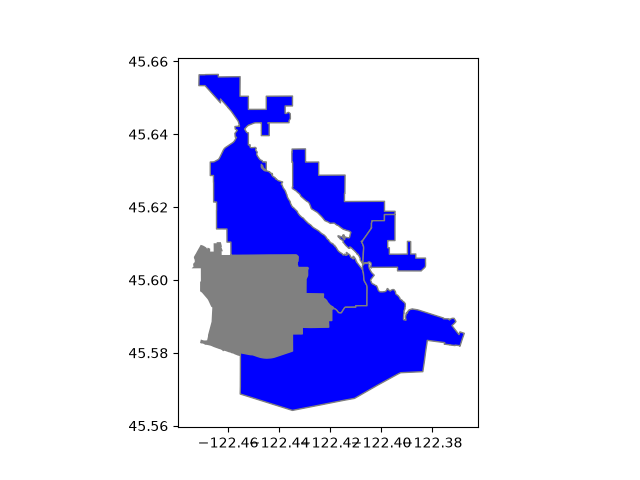

,OBJECTID,Ward,PublishDt,geometry,Ward_Cat,Councilors,At_Large,index_right
0,1,2.0,1793389813000,"MULTIPOLYGON (((-122.46384 45.65643, -122.4689...",Ward 2,Martin Elzingre & Tim Hein,John Svilarich,1
3,4,1.0,1793389813000,"MULTIPOLYGON (((-122.40617 45.60458, -122.4066...",Ward 1,Marilyn Boerke & John Nohr,John Svilarich,0


In [95]:
# find the ward that the point is in using a spatial join
ward_selection = ward_data.sjoin(
    gdf_addresses.geometry.to_frame(), predicate = 'contains'
)
base = ward_data.plot(facecolor='gray')
ward_selection.plot(ax=base,facecolor='blue',edgecolor='gray')
# points.plot(ax=base,color='red',markersize=5)
plt.show()
ward_selection